# Blow ups

In [1]:
import sys
sys.path.append('../../../')

import matplotlib.pyplot as plt

# Import methods
import QGP.Defocusing.Methods as Def
import QGP.Focusing.Methods as Foc
from QGP.Soliton_Gen import *
from Utilities import *

import config
path_save_local = "Img/Local/"

# Energies and values

In [3]:
A = 0.65
def norm_L2_gauss(sigma, A=A):
    output = A**2 * np.sqrt(np.pi) * sigma
    return np.sqrt(output)

def norm_L2_sech(sigma, A=A):
    output = 2 * A**2 * sigma
    return np.sqrt(output)

def norm_H1_gauss(sigma, A=A):
    output = A**2 * np.sqrt(np.pi) * (1 + 2*sigma**2) / (2 * sigma)
    return np.sqrt(output)

def norm_H1_sech(sigma, A=A):
    output = 2 * A**2 * (1 + 3*sigma**2) / (3 * sigma)
    return np.sqrt(output)


def norm_H2_gauss(sigma, A=A):
    output = A**2 * np.sqrt(np.pi) * (3 + 2*sigma**2 + 4*sigma**4) / (4 * sigma**3)
    return np.sqrt(output)

def norm_H2_sech(sigma, A=A):
    output = 2 * A**2 * (7 + 5*sigma**2 + 15*sigma**4) / (15 * sigma**3)
    return np.sqrt(output)


def E_gauss(sigma, A=A):
    output = A**2 * np.sqrt(np.pi) * (2 - np.sqrt(2) * A**2 + np.sqrt(2) * A**2 * sigma**2) / (8 * sigma)
    return output

def E_sech(sigma, A=A):
    output = A**2 * (5 - 4 * A**2 + 5 * A**2 * sigma**2) / (15 * sigma)
    return output

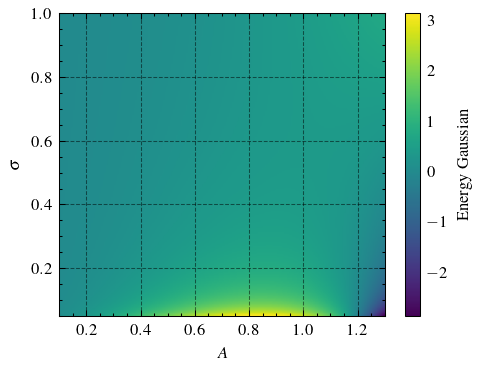

In [4]:
# Crea una malla de puntos
a_s = np.linspace(0.1, 1.3, 200)
ss = np.linspace(0.05, 1, 200)
As, Ss = np.meshgrid(a_s, ss)
Energy_gauss = E_gauss(Ss, As)
Energy_sech = E_sech(Ss, As)

# Mapa de calor
plt.imshow(Energy_gauss, extent=[a_s.min(), a_s.max(), ss.min(), ss.max()],
           origin='lower', aspect='auto', cmap='viridis')
plt.colorbar(label="Energy Gaussian")
plt.xlabel(r'$A$')
plt.ylabel(r'$\sigma$')
plt.show()

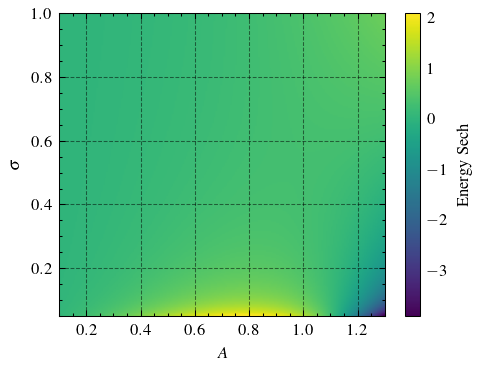

In [71]:
# Mapa de calor
plt.imshow(Energy_sech, extent=[a_s.min(), a_s.max(), ss.min(), ss.max()],
           origin='lower', aspect='auto', cmap='viridis')
plt.colorbar(label="Energy Sech")
plt.xlabel(r'$A$')
plt.ylabel(r'$\sigma$')
plt.show()

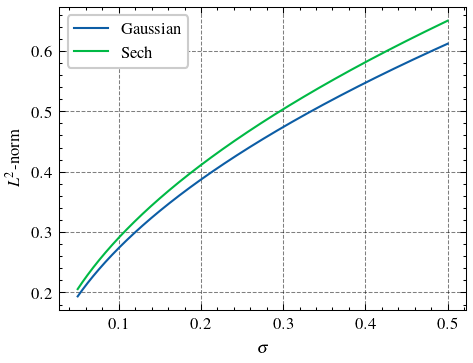

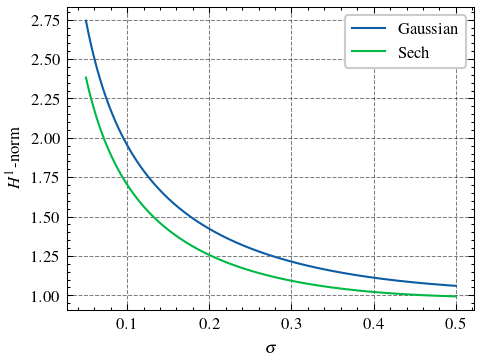

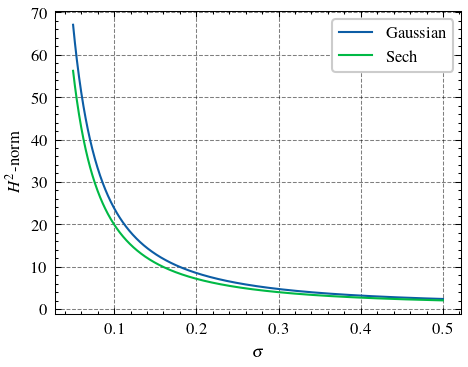

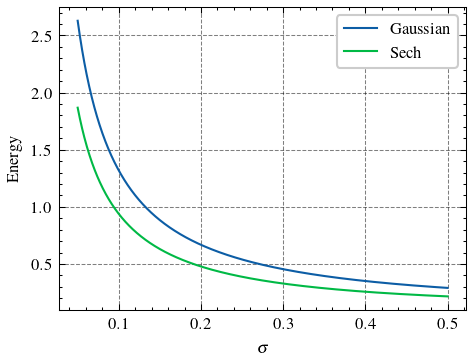

In [36]:
sigmas = np.linspace(0.05, 0.5, 1_000)
#A = 0.65
#As = np.linspace(0.62, 0.7, 1_000)
#sigma = 0.1

plt.plot(sigmas, norm_L2_gauss(sigmas), "-", label="Gaussian")
plt.plot(sigmas, norm_L2_sech(sigmas), "-", label="Sech")
#plt.vlines(0.65, 0.065, 0.1, ls="--", color="red", alpha=.5, label="0.65")
plt.ylabel(r"$L^2$-norm")
plt.xlabel(r"$\sigma$")

plt.legend()
plt.show()

plt.plot(sigmas, norm_H1_gauss(sigmas), "-", label="Gaussian")
plt.plot(sigmas, norm_H1_sech(sigmas), "-", label="Sech")
#plt.vlines(0.65, 2.7, 4.5, ls="--", color="red", alpha=.5, label="0.65")
plt.ylabel(r"$H^1$-norm")
plt.xlabel(r"$\sigma$")

plt.legend()
plt.show()

plt.plot(sigmas, norm_H2_gauss(sigmas), "-", label="Gaussian")
plt.plot(sigmas, norm_H2_sech(sigmas), "-", label="Sech")
#plt.vlines(0.65, 350, 670, ls="--", color="red", alpha=.5, label="0.65")
plt.ylabel(r"$H^2$-norm")
plt.xlabel(r"$\sigma$")


plt.legend()
plt.show()

plt.plot(sigmas, E_gauss(sigmas), "-", label="Gaussian")
plt.plot(sigmas, E_sech(sigmas), "-", label="Sech")
#plt.vlines(0.65, 0.8, 1.5, ls="--", color="red", alpha=.5, label="0.65")
plt.ylabel("Energy")
plt.xlabel(r"$\sigma$")


plt.legend()
plt.show()

# Blow up time estimation

In [4]:
time_file = gzip.GzipFile("../../../Heaven_scripts/Results/Blow_up/blow_up_time/t_guesses.npy.gz", "r")
blow_up_times = np.load(time_file)

In [6]:
blow_up_times[blow_up_times!=0][-1]

0.002158186420517196

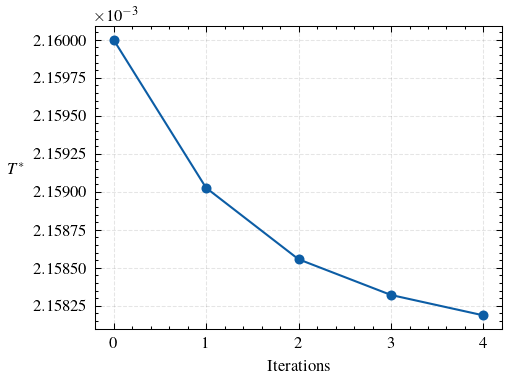

In [12]:
plt.plot(blow_up_times[blow_up_times!=0])
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="y")
plt.ylabel(r"$T^*$", rotation='horizontal', ha='right')
plt.xlabel("Iterations")

plt.savefig("Img/Heaven/time_est.pdf", dpi=300, bbox_inches = "tight")
plt.show()

# Gaussian test

## Blow up tester

In [2]:
A = 0.65 #np.sqrt(2)/2 + 0.01 #1 #0.625 #0.65
sigma = 1/10

def gaussian(x, sigma=sigma):
    output = A * np.exp(-x**2/(2 * sigma**2))
    return output

In [3]:
L = np.pi
N = 15_000
k = 1
Nt = 5_000 #10_000
tf = 2.25e-3
pars = {"k":k}

w_gauss_BL = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_gauss_BL.set_init_condition(gaussian)
w_gauss_BL.solve()#method="fixed point")

Iteration  1  of  5000 . Newton Error:  1.0888457458336677e-14 . Total iteration:  1
Iteration  2  of  5000 . Newton Error:  1.0888602272490135e-14 . Total iteration:  1
Iteration  3  of  5000 . Newton Error:  1.0888414572074729e-14 . Total iteration:  1
Iteration  4  of  5000 . Newton Error:  1.0888356808088569e-14 . Total iteration:  1
Iteration  5  of  5000 . Newton Error:  1.0888460366060152e-14 . Total iteration:  1
Iteration  6  of  5000 . Newton Error:  1.0888508071925837e-14 . Total iteration:  1
Iteration  7  of  5000 . Newton Error:  1.0888510455615121e-14 . Total iteration:  1
Iteration  8  of  5000 . Newton Error:  1.0888704678556458e-14 . Total iteration:  1
Iteration  9  of  5000 . Newton Error:  1.088848774624357e-14 . Total iteration:  1
Iteration  10  of  5000 . Newton Error:  1.0888265392584073e-14 . Total iteration:  1
Iteration  11  of  5000 . Newton Error:  1.0888621129044024e-14 . Total iteration:  1
Iteration  12  of  5000 . Newton Error:  1.088837005067316e-14 .

KeyboardInterrupt: 

In [ ]:
w_gauss_BL_max = np_norm(w_gauss_BL.w, np.inf, axis=1)

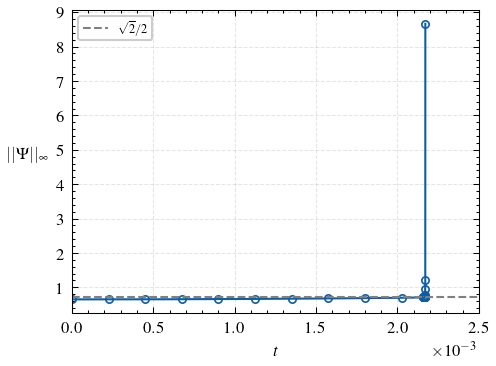

In [ ]:
sol_lim = np.sqrt(2)/2
cond = w_gauss_BL_max!=0

cond_1_markers = np.where(w_gauss_BL_max<sol_lim)[0]
mark_indices_1 = cond_1_markers[::500]
cond_2_markers = np.where(w_gauss_BL_max>sol_lim)[0]
mark_indices_2 = cond_2_markers

mark_indices = np.append(mark_indices_1, mark_indices_2)

plt.plot(w_gauss_BL.t[cond], w_gauss_BL_max[cond], markevery=mark_indices, markerfacecolor='none', ms=3.5) #

plt.xlabel(r"$t$")
plt.ylabel(r"$||\Psi||_\infty$", rotation='horizontal', ha='right')
plt.hlines(sol_lim, 0, 3.5e-3, ls="--", color="gray", label=r"$\sqrt{2}/2$")
#plt.ylim(0.6, 1)
plt.xlim(0, 2.5e-3)
plt.legend(fontsize=6)
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
#plt.savefig(path_save+"Blow_up_As_inf_norm.pdf", dpi=300, bbox_inches = "tight")
plt.show()

## $A$ greater

In [10]:
A = 2 #np.sqrt(2)/2 + 0.01 #1 #0.625 #0.65
sigma = 1/10

def gaussian(x, sigma=sigma):
    output = A * np.exp(-x**2/(2 * sigma**2))
    return output

In [11]:
L = np.pi
N = 10_000
k = 1
Nt = 2_000 #10_000
tf = 1.9e-5
pars = {"k":k}

w_gauss_A_sqrt_2 = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_gauss_A_sqrt_2.set_init_condition(gaussian)
w_gauss_A_sqrt_2.solve()#method="fixed point")

Iteration  1  of  2000 . Newton Error:  7.105905254157149e-16 . Total iteration:  2
Iteration  2  of  2000 . Newton Error:  7.108938481974463e-16 . Total iteration:  2
Iteration  3  of  2000 . Newton Error:  7.109626916977668e-16 . Total iteration:  2
Iteration  4  of  2000 . Newton Error:  7.10915940070601e-16 . Total iteration:  2
Iteration  5  of  2000 . Newton Error:  7.109639662247567e-16 . Total iteration:  2
Iteration  6  of  2000 . Newton Error:  7.105267888750274e-16 . Total iteration:  2
Iteration  7  of  2000 . Newton Error:  7.108047898332832e-16 . Total iteration:  2
Iteration  8  of  2000 . Newton Error:  7.107603857189617e-16 . Total iteration:  2
Iteration  9  of  2000 . Newton Error:  7.10895130406882e-16 . Total iteration:  2
Iteration  10  of  2000 . Newton Error:  7.109832277627699e-16 . Total iteration:  2
Iteration  11  of  2000 . Newton Error:  7.111345152138849e-16 . Total iteration:  2
Iteration  12  of  2000 . Newton Error:  7.110041013337895e-16 . Total itera

(-100.0, 100.0)

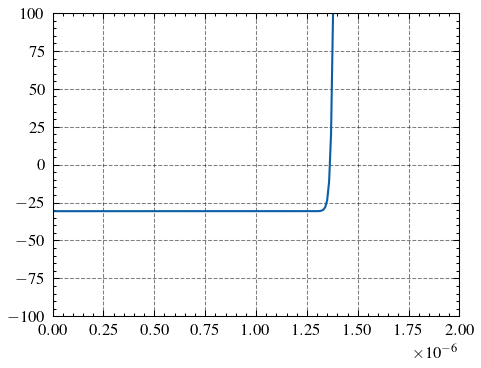

In [23]:
plt.plot(w_gauss_A_sqrt_2.t, w_gauss_A_sqrt_2.get_energy(), "-")
plt.xlim(0, 2e-6)
plt.ylim(-100, 100)

In [26]:
virial_A_sqrt_2 = w_gauss_A_sqrt_2.get_virial()

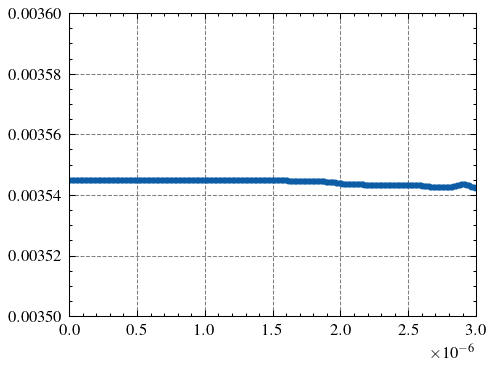

In [32]:
plt.plot(w_gauss_A_sqrt_2.t, virial_A_sqrt_2, ".-")
plt.xlim(0, 3e-6)
plt.ylim(3.5e-3, 3.6e-3)
plt.show()

MovieWriter ffmpeg unavailable; using Pillow instead.


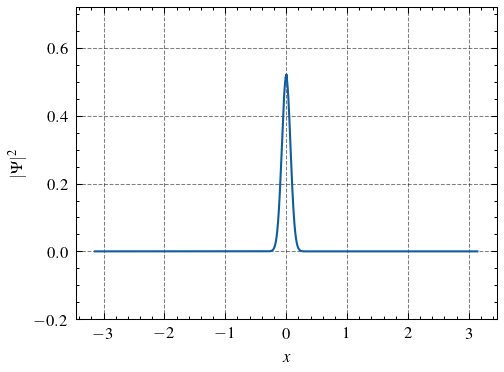

In [207]:
w_gauss_A_sqrt_2.animate_solution("Img/Local/gauss_A_sqrt_2.gif", 100)

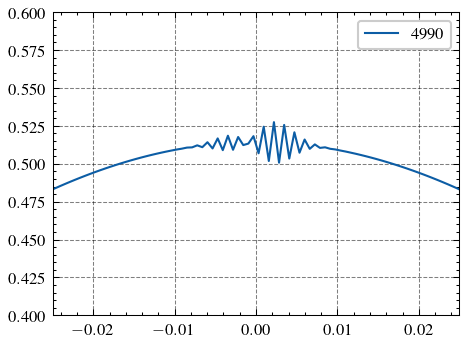

In [212]:
j = 4990
plt.plot(w_gauss_A_sqrt_2.x, norm(w_gauss_A_sqrt_2.w[j]), "-", label=j)
plt.legend()
plt.xlim(-.025, .025)
plt.ylim(0.4, 0.6)
plt.show()

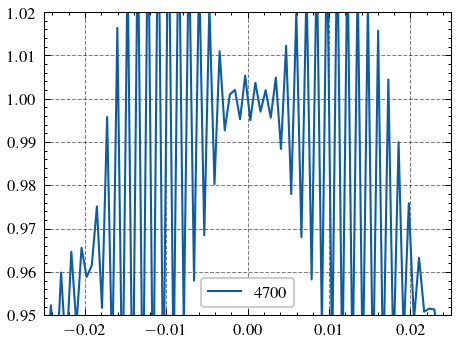

In [195]:
j = 4700
plt.plot(w_gauss_A_1.x, norm(w_gauss_A_1.w[j]), "-", label=j)
plt.legend()
plt.xlim(-.025, .025)
plt.ylim(0.95, 1.02)
plt.show()

## $\kappa$ tests

In [2]:
k_1 = 1/8
k_2 = 1
k_3 = 4
k_4 = 8

def A_k(k, eps=1e-1):
    return 1/np.sqrt(2*k) - eps

sigma = 1/10

def gaussian(x, A, sigma=sigma):
    output = A * np.exp(-x**2/(2 * sigma**2))
    return output

In [3]:
L = np.pi
N = 10_000
Nt = 10_000 #10_000
tf = 1.4e-3
pars_1 = {"k":k_1}
pars_2 = {"k":k_2}
pars_3 = {"k":k_3}
pars_4 = {"k":k_4}

A_1 = A_k(k_1, eps=5e-2)
gaussian_k_1_init = lambda x: gaussian(x, A_1)

w_gauss_k_1 = Def.CNFD(L, N, Nt, tf, pars_1, "neumann", order=2)
w_gauss_k_1.set_init_condition(gaussian_k_1_init)
w_gauss_k_1.solve()

Iteration  1  of  10000 . Newton Error:  1.2225349264318737e-15 . Total iteration:  1
Iteration  2  of  10000 . Newton Error:  1.2228045689459702e-15 . Total iteration:  1
Iteration  3  of  10000 . Newton Error:  1.2228445816428834e-15 . Total iteration:  1
Iteration  4  of  10000 . Newton Error:  1.222734205370389e-15 . Total iteration:  1
Iteration  5  of  10000 . Newton Error:  1.2233367334476693e-15 . Total iteration:  1
Iteration  6  of  10000 . Newton Error:  1.2229116243734933e-15 . Total iteration:  1
Iteration  7  of  10000 . Newton Error:  1.2227509540172906e-15 . Total iteration:  1
Iteration  8  of  10000 . Newton Error:  1.2227671279741455e-15 . Total iteration:  1
Iteration  9  of  10000 . Newton Error:  1.2224567204569599e-15 . Total iteration:  1
Iteration  10  of  10000 . Newton Error:  1.22248176565453e-15 . Total iteration:  1
Iteration  11  of  10000 . Newton Error:  1.2221301361362186e-15 . Total iteration:  1
Iteration  12  of  10000 . Newton Error:  1.22328037724

In [4]:
A_2 = A_k(k_2, eps=5e-2)
gaussian_k_2_init = lambda x: gaussian(x, A_2)
tf = 2e-3

w_gauss_k_2 = Def.CNFD(L, N, Nt, tf, pars_2, "neumann", order=2)
w_gauss_k_2.set_init_condition(gaussian_k_2_init)
w_gauss_k_2.solve()#method="fixed point")

Iteration  1  of  10000 . Newton Error:  9.972352279513054e-16 . Total iteration:  1
Iteration  2  of  10000 . Newton Error:  9.974450172161834e-16 . Total iteration:  1
Iteration  3  of  10000 . Newton Error:  9.972505093064732e-16 . Total iteration:  1
Iteration  4  of  10000 . Newton Error:  9.972724589481992e-16 . Total iteration:  1
Iteration  5  of  10000 . Newton Error:  9.979037080740859e-16 . Total iteration:  1
Iteration  6  of  10000 . Newton Error:  9.975569532606167e-16 . Total iteration:  1
Iteration  7  of  10000 . Newton Error:  9.97422229703888e-16 . Total iteration:  1
Iteration  8  of  10000 . Newton Error:  9.9750376020507e-16 . Total iteration:  1
Iteration  9  of  10000 . Newton Error:  9.974622547665787e-16 . Total iteration:  1
Iteration  10  of  10000 . Newton Error:  9.976664269641415e-16 . Total iteration:  1
Iteration  11  of  10000 . Newton Error:  9.975063294431547e-16 . Total iteration:  1
Iteration  12  of  10000 . Newton Error:  9.974154453164876e-16 . 

In [5]:
A_3 = A_k(k_3, eps=1e-2)
gaussian_k_3_init = lambda x: gaussian(x, A_3)
tf = 1.3e-3
w_gauss_k_3 = Def.CNFD(L, N, Nt, tf, pars_3, "neumann", order=2)
w_gauss_k_3.set_init_condition(gaussian_k_3_init)
w_gauss_k_3.solve()#method="fixed point")

Iteration  1  of  10000 . Newton Error:  1.6417566165841671e-16 . Total iteration:  1
Iteration  2  of  10000 . Newton Error:  1.6417971505800806e-16 . Total iteration:  1
Iteration  3  of  10000 . Newton Error:  1.6404659490552133e-16 . Total iteration:  1
Iteration  4  of  10000 . Newton Error:  1.6425848349807893e-16 . Total iteration:  1
Iteration  5  of  10000 . Newton Error:  1.64135079748232e-16 . Total iteration:  1
Iteration  6  of  10000 . Newton Error:  1.642589423742823e-16 . Total iteration:  1
Iteration  7  of  10000 . Newton Error:  1.642471306232524e-16 . Total iteration:  1
Iteration  8  of  10000 . Newton Error:  1.642286887962066e-16 . Total iteration:  1
Iteration  9  of  10000 . Newton Error:  1.6434307151811286e-16 . Total iteration:  1
Iteration  10  of  10000 . Newton Error:  1.6418797675493742e-16 . Total iteration:  1
Iteration  11  of  10000 . Newton Error:  1.6426363249316693e-16 . Total iteration:  1
Iteration  12  of  10000 . Newton Error:  1.6428181495724

In [6]:
A_4 = A_k(k_4, eps=1e-2)
gaussian_k_4_init = lambda x: gaussian(x, A_4)
tf = 1.5e-3
w_gauss_k_4 = Def.CNFD(L, N, Nt, tf, pars_4, "neumann", order=2)
w_gauss_k_4.set_init_condition(gaussian_k_4_init)
w_gauss_k_4.solve()#method="fixed point")

Iteration  1  of  10000 . Newton Error:  1.6876567180298767e-16 . Total iteration:  1
Iteration  2  of  10000 . Newton Error:  1.6886788515985392e-16 . Total iteration:  1
Iteration  3  of  10000 . Newton Error:  1.6881821878910428e-16 . Total iteration:  1
Iteration  4  of  10000 . Newton Error:  1.6884045530678067e-16 . Total iteration:  1
Iteration  5  of  10000 . Newton Error:  1.6889724359860292e-16 . Total iteration:  1
Iteration  6  of  10000 . Newton Error:  1.6877175147306998e-16 . Total iteration:  1
Iteration  7  of  10000 . Newton Error:  1.687815919962123e-16 . Total iteration:  1
Iteration  8  of  10000 . Newton Error:  1.6880855918878563e-16 . Total iteration:  1
Iteration  9  of  10000 . Newton Error:  1.6890649868733906e-16 . Total iteration:  1
Iteration  10  of  10000 . Newton Error:  1.6892092637804132e-16 . Total iteration:  1
Iteration  11  of  10000 . Newton Error:  1.6880804854364837e-16 . Total iteration:  1
Iteration  12  of  10000 . Newton Error:  1.688184764

In [7]:
w_gauss_k_1_max = np_norm(w_gauss_k_1.w, np.inf, axis=1)
w_gauss_k_2_max = np_norm(w_gauss_k_2.w, np.inf, axis=1)
w_gauss_k_3_max = np_norm(w_gauss_k_3.w, np.inf, axis=1)
w_gauss_k_4_max = np_norm(w_gauss_k_4.w, np.inf, axis=1)

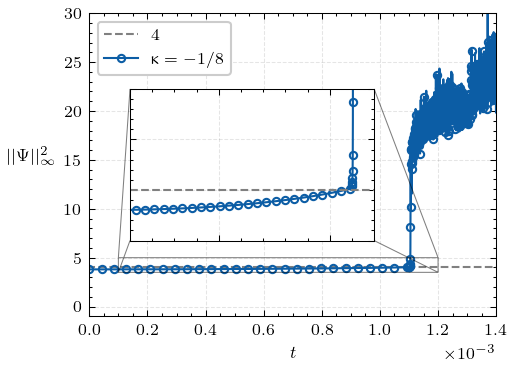

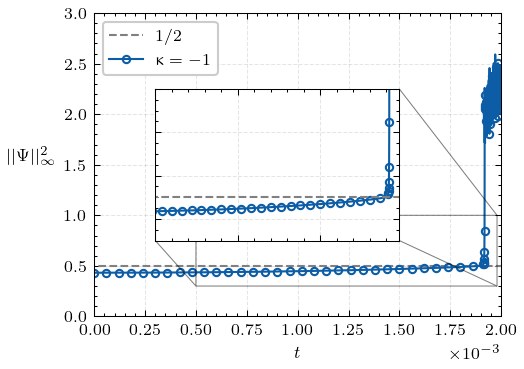

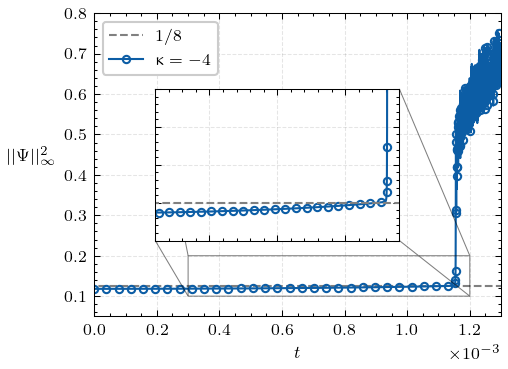

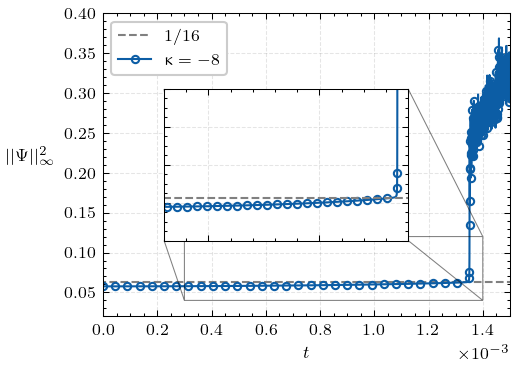

In [9]:
from fractions import Fraction

ks = [k_1, k_2, k_3, k_4]
w_gauss_ks_max = [w_gauss_k_1_max, w_gauss_k_2_max, w_gauss_k_3_max, w_gauss_k_4_max]
w_gauss_ks = [w_gauss_k_1, w_gauss_k_2, w_gauss_k_3, w_gauss_k_4]
ax_mini_insets = [[0.1, 0.25, 0.6, 0.5], [0.15, 0.25, 0.6, 0.5],
                  [0.15, 0.25, 0.6, 0.5], [0.15, 0.25, 0.6, 0.5]]

ax_mini_limits = [[(1e-4, 1.2e-3), (3.5, 5)], [(5e-4, 1.98e-3), (0.3, 1)],
                 [(3e-4, 1.2e-3), (0.1, 0.2)], [(3e-4, 1.4e-3), (0.04, .12)]]

ax_limits = [(-1, 30), (0, 3), (0.05, 0.8), (0.02, .4)]

for j in range(len(ks)):
    k = ks[j]
    w_gauss_k_max = w_gauss_ks_max[j]
    w_gauss_k = w_gauss_ks[j]
    ax_mini_inset = ax_mini_insets[j]
    ax_mini_lims = ax_mini_limits[j]
    ax_limit = ax_limits[j]

    sol_lim = 1/np.sqrt(2*k)+1e-2
    cond = w_gauss_k_max>0

    cond_1_markers = np.where(w_gauss_k_max[cond]<sol_lim)[0]
    mark_indices_1 = cond_1_markers[::300]

    cond_2_markers = np.where(w_gauss_k_max[cond]>sol_lim)[0]
    mark_indices_2 = cond_2_markers[::5]
    mark_indices = np.append(mark_indices_1, mark_indices_2)

    guess = 1/np.sqrt(2*k)**2

    fig = plt.figure()
    ax = fig.add_subplot(111)

    ax.hlines(guess, w_gauss_k.t[w_gauss_k_max>0][0]-10, w_gauss_k.t[w_gauss_k_max>0][-1]+10,
           ls="--", color="gray", label=fr"${Fraction(guess).limit_denominator()}$")

    ax.plot(w_gauss_k.t[w_gauss_k_max>0], w_gauss_k_max[w_gauss_k_max>0]**2, 
         ms=3.5, markevery=mark_indices, label=fr"$\upkappa = -{Fraction(k).limit_denominator()}$", 
            markerfacecolor='none')

    ax_mini = ax.inset_axes(ax_mini_inset)

    ax_mini.plot(w_gauss_k.t[w_gauss_k_max>0], w_gauss_k_max[w_gauss_k_max>0]**2, 
         ms=3.5, markevery=mark_indices, markerfacecolor='none')
    ax_mini.hlines(guess, w_gauss_k.t[w_gauss_k_max>0][0], w_gauss_k.t[w_gauss_k_max>0][-1],
           ls="--", color="gray", label=fr"${Fraction(guess).limit_denominator()}$")

    ax_mini.set_xlim(ax_mini_lims[0])
    ax_mini.set_ylim(ax_mini_lims[1])

    ax_mini.set_xticklabels('')
    ax_mini.set_yticklabels('')
    #ax_mini.grid(linewidth=.5, alpha=.1)
    inset_indicator = ax.indicate_inset_zoom(ax_mini, alpha=.5, label="Zoom", edgecolor="black", lw=.5)

    inset_indicator.connectors[0].set_visible(True)
    inset_indicator.connectors[1].set_visible(True)
    inset_indicator.connectors[2].set_visible(True)
    inset_indicator.connectors[3].set_visible(True)
    
    ax.set_ylim(ax_limit)
    ax.set_xlim(w_gauss_k.t[w_gauss_k_max>0][0], w_gauss_k.t[w_gauss_k_max>0][-1])
    ax.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")

    ax.set_xlabel(r"$t$")
    ax.set_ylabel(r"$||\Psi||^2_\infty$", rotation='horizontal', ha='right')
    #ax.grid(linewidth=.5, alpha=.1)

    plt.legend()
    plt.savefig(path_save_local+f"Gauss_k/Blow_up_k_{k}.pdf", dpi=300, bbox_inches = "tight")
    plt.show()

## Gaussian $\sigma$'s comparisson

In [5]:
A = 0.631 #0.65 #0.625 #0.65
sigma_1 = 1/10
sigma_2 = 2 * sigma_1
sigma_3 = sigma_1 / 2

def gaussian(x, sigma):
    output = A * np.exp(-x**2/(2 * sigma**2))
    return output

gauss_1 = lambda x: gaussian(x, sigma=sigma_1)
gauss_2 = lambda x: gaussian(x, sigma=sigma_2)
gauss_3 = lambda x: gaussian(x, sigma=sigma_3)

In [93]:
L = np.pi
N = 10_000
k = 1 # 5/3
Nt = 10_000 #10_000
tf = 1e-2 #2.25e-3
pars = {"k":k}

w_gauss_1 = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_gauss_1.set_init_condition(gauss_1)
w_gauss_1.solve()#method="fixed point")

Iteration  1  of  10000 . Newton Error:  1.194138194266018e-13 . Total iteration:  2
Iteration  2  of  10000 . Newton Error:  1.1941342025423304e-13 . Total iteration:  2
Iteration  3  of  10000 . Newton Error:  1.1941348150965435e-13 . Total iteration:  2
Iteration  4  of  10000 . Newton Error:  1.1941412454226532e-13 . Total iteration:  2
Iteration  5  of  10000 . Newton Error:  1.1941455794246525e-13 . Total iteration:  2
Iteration  6  of  10000 . Newton Error:  1.194150045352871e-13 . Total iteration:  2
Iteration  7  of  10000 . Newton Error:  1.1941604191877038e-13 . Total iteration:  2
Iteration  8  of  10000 . Newton Error:  1.1941654077144647e-13 . Total iteration:  2
Iteration  9  of  10000 . Newton Error:  1.1941766259724996e-13 . Total iteration:  2
Iteration  10  of  10000 . Newton Error:  1.1941865645466987e-13 . Total iteration:  2
Iteration  11  of  10000 . Newton Error:  1.1942067842571478e-13 . Total iteration:  2
Iteration  12  of  10000 . Newton Error:  1.1942180706

In [8]:
L = np.pi
N = 10_000
k = 1
Nt = 10_000 #10_000
tf = 1e-3 #2.25e-3
pars = {"k":k}

w_gauss_2 = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_gauss_2.set_init_condition(gauss_2)
w_gauss_2.solve()

Iteration  1  of  10000 . Newton Error:  4.1673043382087626e-17 . Total iteration:  2
Iteration  2  of  10000 . Newton Error:  4.4384395150765146e-17 . Total iteration:  2
Iteration  3  of  10000 . Newton Error:  4.184949192334096e-17 . Total iteration:  2
Iteration  4  of  10000 . Newton Error:  4.2568546032892195e-17 . Total iteration:  2
Iteration  5  of  10000 . Newton Error:  4.111370621047101e-17 . Total iteration:  2
Iteration  6  of  10000 . Newton Error:  4.255476041376812e-17 . Total iteration:  2
Iteration  7  of  10000 . Newton Error:  4.317780692177798e-17 . Total iteration:  2
Iteration  8  of  10000 . Newton Error:  4.42115369045459e-17 . Total iteration:  2
Iteration  9  of  10000 . Newton Error:  4.4668504289613934e-17 . Total iteration:  2
Iteration  10  of  10000 . Newton Error:  4.3319806249998797e-17 . Total iteration:  2
Iteration  11  of  10000 . Newton Error:  4.122297805241045e-17 . Total iteration:  2
Iteration  12  of  10000 . Newton Error:  4.320244264048644

In [14]:
L = np.pi
N = 10_000
k = 1
Nt = 2_000 #10_000
tf = 3e-2 #2.25e-3
pars = {"k":k}

w_gauss_3 = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_gauss_3.set_init_condition(gauss_3)
w_gauss_3.solve()

Iteration  1  of  2000 . Newton Error:  3.1590412316391912e-12 . Total iteration:  4
Iteration  2  of  2000 . Newton Error:  3.824068925342029e-14 . Total iteration:  5
Iteration  3  of  2000 . Newton Error:  1.3376275230152897e-11 . Total iteration:  5
Iteration  4  of  2000 . Newton Error:  2.5015407166540176e-15 . Total iteration:  5
Iteration  5  of  2000 . Newton Error:  3.1203073488781316e-13 . Total iteration:  4
Iteration  6  of  2000 . Newton Error:  2.8461831449002983e-14 . Total iteration:  4
Iteration  7  of  2000 . Newton Error:  8.767720721814765e-16 . Total iteration:  4
Iteration  8  of  2000 . Newton Error:  3.0359999448389356e-16 . Total iteration:  4
Iteration  9  of  2000 . Newton Error:  2.975746078453178e-16 . Total iteration:  4
Iteration  10  of  2000 . Newton Error:  2.9887629490919926e-16 . Total iteration:  4
Iteration  11  of  2000 . Newton Error:  2.2809464850280336e-16 . Total iteration:  4
Iteration  12  of  2000 . Newton Error:  3.554694150906777e-16 . T

MovieWriter ffmpeg unavailable; using Pillow instead.


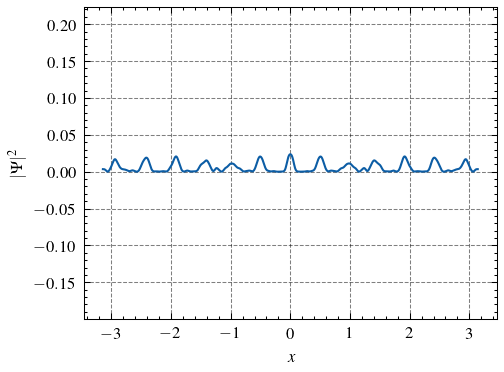

In [15]:
w_gauss_3.animate_solution("test.gif", 50)

In [16]:
w_gauss_3_max = np_norm(w_gauss_3.w, np.inf, axis=1)

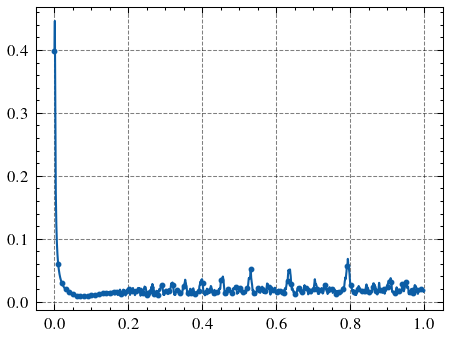

In [17]:
plt.plot(w_gauss_3.t, w_gauss_3_max**2, markevery=20, ms=2)
#plt.ylim(0.35, 1)
plt.show()

In [27]:
A = 0.64 #0.65 #0.625 #0.65 #0.638
sigma = 0.5

def gaussian(x, sigma):
    output = A * np.exp(-x**2/(2 * sigma**2))
    return output

gauss = lambda x: gaussian(x, sigma=sigma)

L = np.pi
N = 10_000
k = 1
Nt = 2_000 #10_000
tf = 1e-1 #2.25e-3
pars = {"k":k}

w_gauss = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_gauss.set_init_condition(gauss)
w_gauss.solve()

Iteration  1  of  2000 . Newton Error:  1.3431403273556656e-12 . Total iteration:  2
Iteration  2  of  2000 . Newton Error:  1.3431401851928238e-12 . Total iteration:  2
Iteration  3  of  2000 . Newton Error:  1.343168437515518e-12 . Total iteration:  2
Iteration  4  of  2000 . Newton Error:  1.3431963276705654e-12 . Total iteration:  2
Iteration  5  of  2000 . Newton Error:  1.3432120432465558e-12 . Total iteration:  2
Iteration  6  of  2000 . Newton Error:  1.3432697880768327e-12 . Total iteration:  2
Iteration  7  of  2000 . Newton Error:  1.3433245427096077e-12 . Total iteration:  2
Iteration  8  of  2000 . Newton Error:  1.3433966865220144e-12 . Total iteration:  2
Iteration  9  of  2000 . Newton Error:  1.343488810172395e-12 . Total iteration:  2
Iteration  10  of  2000 . Newton Error:  1.3435499758079542e-12 . Total iteration:  2
Iteration  11  of  2000 . Newton Error:  1.3436908693224504e-12 . Total iteration:  2
Iteration  12  of  2000 . Newton Error:  1.3437739502534177e-12 .

In [30]:
w_gauss_max = np_norm(w_gauss.w, np.inf, axis=1)

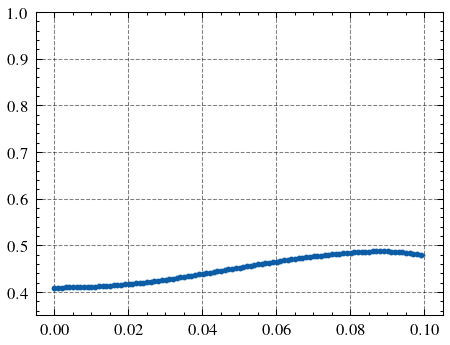

In [31]:
plt.plot(w_gauss.t, w_gauss_max**2, markevery=20, ms=2)
plt.ylim(0.35, 1)
plt.show()

## Gif creator

MovieWriter ffmpeg unavailable; using Pillow instead.


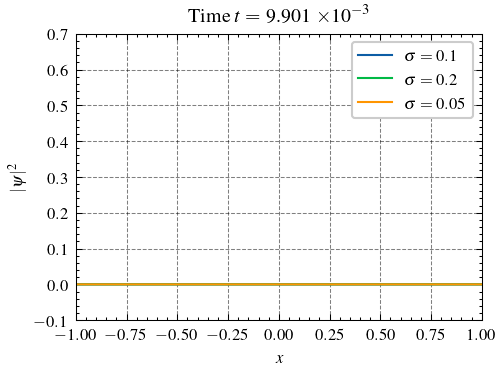

In [97]:
# Create figure
N_frames = 150 # CAMBIAR A 10

x_indices = np.abs(w_gauss_1.x)<1

fig, ax = plt.subplots()
line1, = ax.plot(w_gauss_1.x[x_indices], norm(w_gauss_1.w[0][x_indices]), "-", label=r"$\sigma = 0.1$")
line2, = ax.plot(w_gauss_2.x[x_indices], norm(w_gauss_2.w[0][x_indices]), "-", label=r"$\sigma = 0.2$")
line3, = ax.plot(w_gauss_3.x[x_indices], norm(w_gauss_3.w[0][x_indices]), "-", label=r"$\sigma = 0.05$")

ax.set_title(r"Time $t = 0$")
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$|\psi|^2$")
ax.set_xlim(-1, 1)
ax.set_ylim(-0.1, 0.7)

fig.tight_layout()

# Animate function
def animate(j):
    dt = w_gauss_1.dt
    t_plot = w_gauss_1.t[j]

    x_indices = np.abs(w_gauss_1.x)<1

    # Update plot
    line1.set_data(w_gauss_1.x[x_indices], norm(w_gauss_1.w[j][x_indices]))
    line2.set_data(w_gauss_2.x[x_indices], norm(w_gauss_2.w[j][x_indices]))
    line3.set_data(w_gauss_3.x[x_indices], norm(w_gauss_3.w[j][x_indices]))
    ax.set_title(r"Time $t =$ {}".format(sci_notation(t_plot, 3)))

    ax.legend()

    return line1, line2, line3,

# Animación
ani = animation.FuncAnimation(fig, animate, frames=np.arange(0, Nt, N_frames), interval=150)

ani.save("Img/Local/gauss_sigmas.gif")
plt.show()

### Guassian $\sigma = 0.2$ and smaller $A$

In [138]:
A = 0.63
sigma_1 = 1/10
sigma_2 = 2 * sigma_1

def gaussian(x, sigma):
    output = A * np.exp(-x**2/(2 * sigma**2))
    return output

gauss_1_A = lambda x: gaussian(x, sigma=sigma_1)
gauss_2_A = lambda x: gaussian(x, sigma=sigma_2)

In [142]:
L = np.pi
N = 10_000
k = 1
Nt = 4_000 #10_000
tf = 1.8e-2 #2.25e-3
pars = {"k":k}

w_gauss_1_A = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_gauss_1_A.set_init_condition(gauss_1_A)
w_gauss_1_A.solve()

Iteration  1  of  4000 . Newton Error:  9.67063733993105e-12 . Total iteration:  2
Iteration  2  of  4000 . Newton Error:  9.670676052393258e-12 . Total iteration:  2
Iteration  3  of  4000 . Newton Error:  9.670875811201328e-12 . Total iteration:  2
Iteration  4  of  4000 . Newton Error:  9.671229793561368e-12 . Total iteration:  2
Iteration  5  of  4000 . Newton Error:  9.671748032958976e-12 . Total iteration:  2
Iteration  6  of  4000 . Newton Error:  9.672422496745747e-12 . Total iteration:  2
Iteration  7  of  4000 . Newton Error:  9.67325656125659e-12 . Total iteration:  2
Iteration  8  of  4000 . Newton Error:  9.674251483004044e-12 . Total iteration:  2
Iteration  9  of  4000 . Newton Error:  9.675404487657348e-12 . Total iteration:  2
Iteration  10  of  4000 . Newton Error:  9.676717148927117e-12 . Total iteration:  2
Iteration  11  of  4000 . Newton Error:  9.678191989949826e-12 . Total iteration:  2
Iteration  12  of  4000 . Newton Error:  9.679824406941389e-12 . Total itera

In [143]:
w_gauss_2_A = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_gauss_2_A.set_init_condition(gauss_2_A)
w_gauss_2_A.solve()

Iteration  1  of  4000 . Newton Error:  2.0361302507300506e-13 . Total iteration:  2
Iteration  2  of  4000 . Newton Error:  2.036119906086124e-13 . Total iteration:  2
Iteration  3  of  4000 . Newton Error:  2.036116855663822e-13 . Total iteration:  2
Iteration  4  of  4000 . Newton Error:  2.0361250035865035e-13 . Total iteration:  2
Iteration  5  of  4000 . Newton Error:  2.0361393205851253e-13 . Total iteration:  2
Iteration  6  of  4000 . Newton Error:  2.0361519128229248e-13 . Total iteration:  2
Iteration  7  of  4000 . Newton Error:  2.036156033859552e-13 . Total iteration:  2
Iteration  8  of  4000 . Newton Error:  2.0361725334698346e-13 . Total iteration:  2
Iteration  9  of  4000 . Newton Error:  2.0361966446595078e-13 . Total iteration:  2
Iteration  10  of  4000 . Newton Error:  2.0362003870104074e-13 . Total iteration:  2
Iteration  11  of  4000 . Newton Error:  2.0362239728508952e-13 . Total iteration:  2
Iteration  12  of  4000 . Newton Error:  2.036249790607518e-13 . T

MovieWriter ffmpeg unavailable; using Pillow instead.


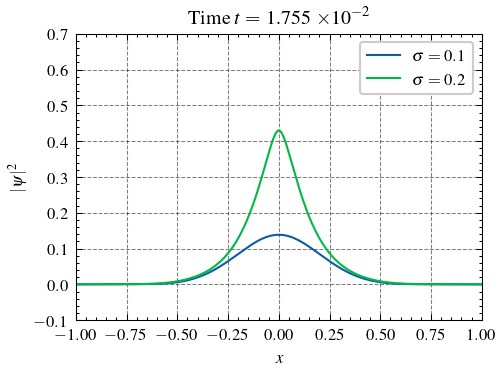

In [144]:
# Create figure
N_frames = 150

x_indices = np.abs(w_gauss_1_A.x)<1

fig, ax = plt.subplots()
line1, = ax.plot(w_gauss_1_A.x[x_indices], norm(w_gauss_1_A.w[0][x_indices]), "-", label=r"$\sigma = 0.1$")
line2, = ax.plot(w_gauss_2_A.x[x_indices], norm(w_gauss_2_A.w[0][x_indices]), "-", label=r"$\sigma = 0.2$")

ax.set_title(r"Time $t = 0$")
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$|\psi|^2$")
ax.set_xlim(-1, 1)
ax.set_ylim(-0.1, 0.7)

fig.tight_layout()

# Animate function
def animate(j):
    dt = w_gauss_1.dt
    t_plot = w_gauss_1_A.t[j]

    x_indices = np.abs(w_gauss_1_A.x)<1

    # Update plot
    line1.set_data(w_gauss_1_A.x[x_indices], norm(w_gauss_1_A.w[j][x_indices]))
    line2.set_data(w_gauss_2_A.x[x_indices], norm(w_gauss_2_A.w[j][x_indices]))
    ax.set_title(r"Time $t =$ {}".format(sci_notation(t_plot, 3)))

    ax.legend()

    return line1, line2,

# Animación
ani = animation.FuncAnimation(fig, animate, frames=np.arange(0, Nt, N_frames), interval=150)

ani.save("Img/Local/gauss_sigmas_A_0_63.gif")
plt.show()

# Guassian-cosine tests

In [25]:
A = 0.65 #0.65
sigma = 0.1 #1/10
l = 15

def gauss_cos_init(x):
    output = A * np.exp(-x**2/(2 * sigma**2)) * np.cos(l*x)
    return output

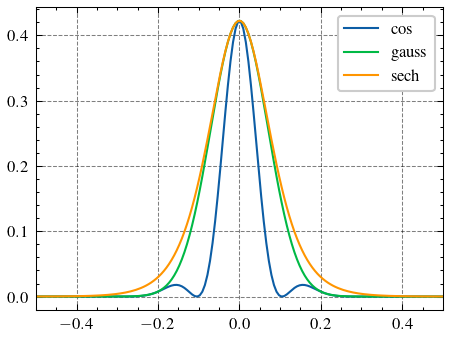

In [26]:
x_plot = np.linspace(-np.pi, np.pi, 1000)

plt.plot(x_plot, norm(gauss_cos_init(x_plot)), "-", label="cos")
plt.plot(x_plot, norm(gaussian(x_plot)), "-", label="gauss")
plt.plot(x_plot, norm(sech_init(x_plot)), "-", label="sech")
plt.legend()
plt.xlim(-0.5, 0.5)
plt.show()

In [29]:
L = np.pi
N = 10_000
k = 1
Nt = 5_000 #10_000
tf = 1.2e-3
pars = {"k":k}

w_cos = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_cos.set_init_condition(gauss_cos_init)
w_cos.solve()#method="fixed point")

Iteration  1  of  5000 . Newton Error:  5.3900043192195024e-14 . Total iteration:  2
Iteration  2  of  5000 . Newton Error:  5.389994723302147e-14 . Total iteration:  2
Iteration  3  of  5000 . Newton Error:  5.39001240895976e-14 . Total iteration:  2
Iteration  4  of  5000 . Newton Error:  5.3900294591578626e-14 . Total iteration:  2
Iteration  5  of  5000 . Newton Error:  5.390028147481502e-14 . Total iteration:  2
Iteration  6  of  5000 . Newton Error:  5.3900668726295125e-14 . Total iteration:  2
Iteration  7  of  5000 . Newton Error:  5.3900571967972696e-14 . Total iteration:  2
Iteration  8  of  5000 . Newton Error:  5.3900712856203614e-14 . Total iteration:  2
Iteration  9  of  5000 . Newton Error:  5.390099572380488e-14 . Total iteration:  2
Iteration  10  of  5000 . Newton Error:  5.390123279070917e-14 . Total iteration:  2
Iteration  11  of  5000 . Newton Error:  5.390156839655797e-14 . Total iteration:  2
Iteration  12  of  5000 . Newton Error:  5.39017773663716e-14 . Total 

MovieWriter ffmpeg unavailable; using Pillow instead.


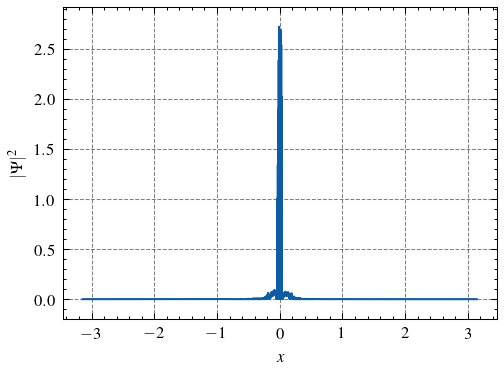

In [30]:
w_cos.animate_solution("Img/Local/gauss_cos_l_15.gif", 50)

# Hyperbolic secant tests

In [4]:
A = 0.65 #0.65
sigma = 0.1 #1/10

def sech_init(x):
    output = A * sech(x/(sigma))
    return output

In [4]:
L = np.pi
N = 10_000
k = 1
Nt = 5_000 #10_000
tf = 1e-2 #2.25e-3
pars = {"k":k}

w_sech = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_sech.set_init_condition(sech_init)
w_sech.solve()#method="fixed point")

Iteration  1  of  5000 . Newton Error:  5.604179621181823e-13 . Total iteration:  2
Iteration  2  of  5000 . Newton Error:  5.604174080535554e-13 . Total iteration:  2
Iteration  3  of  5000 . Newton Error:  5.604205969611779e-13 . Total iteration:  2
Iteration  4  of  5000 . Newton Error:  5.60427989305077e-13 . Total iteration:  2
Iteration  5  of  5000 . Newton Error:  5.604375696158919e-13 . Total iteration:  2
Iteration  6  of  5000 . Newton Error:  5.604513784113694e-13 . Total iteration:  2
Iteration  7  of  5000 . Newton Error:  5.604697278285715e-13 . Total iteration:  2
Iteration  8  of  5000 . Newton Error:  5.60490105395122e-13 . Total iteration:  2
Iteration  9  of  5000 . Newton Error:  5.60513663914858e-13 . Total iteration:  2
Iteration  10  of  5000 . Newton Error:  5.605418259111519e-13 . Total iteration:  2
Iteration  11  of  5000 . Newton Error:  5.605727351034907e-13 . Total iteration:  2
Iteration  12  of  5000 . Newton Error:  5.606076865072622e-13 . Total iterat

MovieWriter ffmpeg unavailable; using Pillow instead.


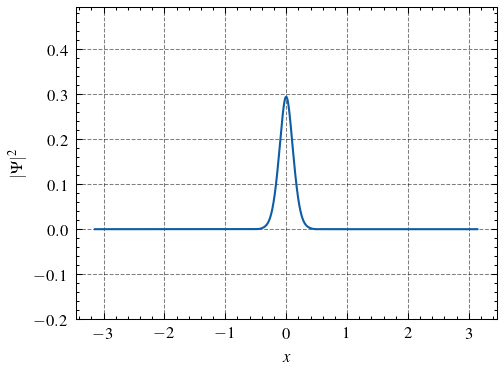

In [5]:
w_sech.animate_solution("Img/Local/sech.gif", 50)

# Generate solutions

In [2]:
A = 0.625 #np.sqrt(2)/2 + 0.01 #1 #0.625 #0.65
sigma = 1/10

def gaussian(x, sigma=sigma):
    output = A * np.exp(-x**2/(2 * sigma**2))
    return output

In [5]:
L = np.pi
N = 5_000
k = 1
Nt = 5_000 #10_000
tf = 1e-1 #2.25e-3
pars = {"k":k}

w_gauss = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_gauss.set_init_condition(gaussian)
w_gauss.solve()#method="fixed point")

Iteration  1  of  5000 . Newton Error:  2.0620320186200038e-16 . Total iteration:  3
Iteration  2  of  5000 . Newton Error:  2.2186705402503363e-16 . Total iteration:  3
Iteration  3  of  5000 . Newton Error:  1.9509967366953795e-16 . Total iteration:  3
Iteration  4  of  5000 . Newton Error:  2.451272965108829e-16 . Total iteration:  3
Iteration  5  of  5000 . Newton Error:  2.0480611320277395e-16 . Total iteration:  3
Iteration  6  of  5000 . Newton Error:  2.1904755877013163e-16 . Total iteration:  3
Iteration  7  of  5000 . Newton Error:  2.361847732358594e-16 . Total iteration:  3
Iteration  8  of  5000 . Newton Error:  2.1950512359116922e-16 . Total iteration:  3
Iteration  9  of  5000 . Newton Error:  2.415791826559442e-16 . Total iteration:  3
Iteration  10  of  5000 . Newton Error:  2.4603655493842603e-16 . Total iteration:  3
Iteration  11  of  5000 . Newton Error:  2.3434001594749893e-16 . Total iteration:  3
Iteration  12  of  5000 . Newton Error:  2.3269766902964625e-16 . 

MovieWriter ffmpeg unavailable; using Pillow instead.


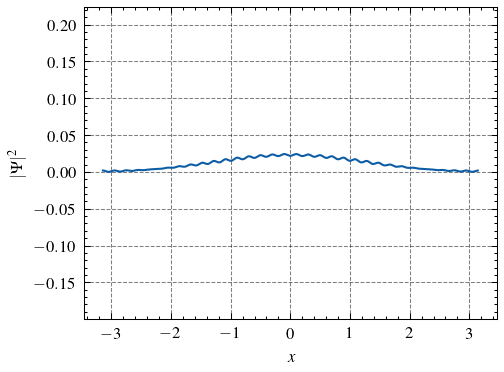

In [6]:
w_gauss.animate_solution("test.gif", 50)

In [10]:
w_gauss_max = np_norm(w_gauss.w, np.inf, axis=1)

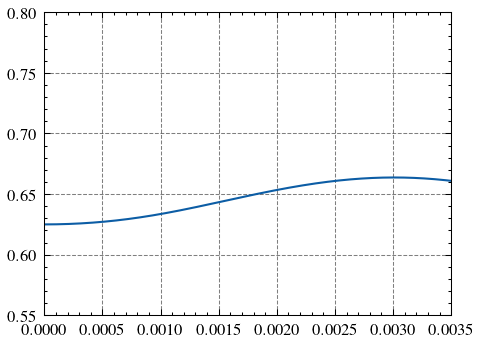

In [16]:
plt.plot(w_gauss.t, w_gauss_max)
plt.ylim(0.55, 0.8)
plt.xlim(0, 3.5e-3)
plt.show()

In [31]:
N_2 = 5_000

w_gauss_N_2 = Def.CNFD(L, N_2, Nt, tf, pars, "neumann", order=2)
w_gauss_N_2.set_init_condition(gaussian)
w_gauss_N_2.solve()

Iteration  1  of  5000 . Newton Error:  1.0879644484973982e-14 . Total iteration:  2
Iteration  2  of  5000 . Newton Error:  1.0879595491478496e-14 . Total iteration:  2
Iteration  3  of  5000 . Newton Error:  1.0879573341532032e-14 . Total iteration:  2
Iteration  4  of  5000 . Newton Error:  1.0879648676460852e-14 . Total iteration:  2
Iteration  5  of  5000 . Newton Error:  1.0879623849058261e-14 . Total iteration:  2
Iteration  6  of  5000 . Newton Error:  1.087963637266877e-14 . Total iteration:  2
Iteration  7  of  5000 . Newton Error:  1.0879688739605548e-14 . Total iteration:  2
Iteration  8  of  5000 . Newton Error:  1.087969229130496e-14 . Total iteration:  2
Iteration  9  of  5000 . Newton Error:  1.0879762097103287e-14 . Total iteration:  2
Iteration  10  of  5000 . Newton Error:  1.0879686335413149e-14 . Total iteration:  2
Iteration  11  of  5000 . Newton Error:  1.0879696912520055e-14 . Total iteration:  2
Iteration  12  of  5000 . Newton Error:  1.0879702808598873e-14 .

# Load solutions (Deprecated)

In [37]:
w_gauss_N_1_Nt_1_file = gzip.GzipFile("Gauss_N_10000_Nt_10000/w_gauss_N_10000.npy.gz", "r")
energy_N_1_Nt_1_file = gzip.GzipFile("Gauss_N_10000_Nt_10000/energy_N_10000.npy.gz", "r")
mass_N_1_Nt_1_file = gzip.GzipFile("Gauss_N_10000_Nt_10000/mass_N_10000.npy.gz", "r")
w_gauss_max_N_1_Nt_1_file = gzip.GzipFile("Gauss_N_10000_Nt_10000/w_gauss_max_N_10000.npy.gz", "r")


w_gauss_N_1_Nt_1 = np.load(w_gauss_N_1_Nt_1_file, allow_pickle=True)
energy_N_1_Nt_1 = np.load(energy_N_1_Nt_1_file)
mass_N_1_Nt_1 = np.load(mass_N_1_Nt_1_file)
w_gauss_max_N_1_Nt_1 = np.load(w_gauss_max_N_1_Nt_1_file)

In [40]:
w_gauss_N_1_Nt_2_file = gzip.GzipFile("Gauss_N_10000_Nt_5000/w_gauss_N_10000.npy.gz", "r")
energy_N_1_Nt_2_file = gzip.GzipFile("Gauss_N_10000_Nt_5000/energy_N_10000.npy.gz", "r")
mass_N_1_Nt_2_file = gzip.GzipFile("Gauss_N_10000_Nt_5000/mass_N_10000.npy.gz", "r")
w_gauss_max_N_1_Nt_2_file = gzip.GzipFile("Gauss_N_10000_Nt_5000/w_gauss_max_N_10000.npy.gz", "r")


w_gauss_N_1_Nt_2 = np.load(w_gauss_N_1_Nt_2_file, allow_pickle=True)
energy_N_1_Nt_2 = np.load(energy_N_1_Nt_2_file)
mass_N_1_Nt_2 = np.load(mass_N_1_Nt_2_file)
w_gauss_max_N_1_Nt_2 = np.load(w_gauss_max_N_1_Nt_2_file)

In [38]:
w_gauss_N_2_Nt_1_file = gzip.GzipFile("Gauss_N_5000_Nt_10000/w_gauss_N_5000.npy.gz", "r")
energy_N_2_Nt_1_file = gzip.GzipFile("Gauss_N_5000_Nt_10000/energy_N_5000.npy.gz", "r")
mass_N_2_Nt_1_file = gzip.GzipFile("Gauss_N_5000_Nt_10000/mass_N_5000.npy.gz", "r")
w_gauss_max_N_2_Nt_1_file = gzip.GzipFile("Gauss_N_5000_Nt_10000/w_gauss_max_N_5000.npy.gz", "r")


w_gauss_N_2_Nt_1 = np.load(w_gauss_N_2_Nt_1_file, allow_pickle=True)
energy_N_2_Nt_1 = np.load(energy_N_2_Nt_1_file)
mass_N_2_Nt_1 = np.load(mass_N_2_Nt_1_file)
w_gauss_max_N_2_Nt_1 = np.load(w_gauss_max_N_2_Nt_1_file)

In [41]:
w_gauss_N_2_Nt_2_file = gzip.GzipFile("Gauss_N_5000_Nt_5000/w_gauss_N_5000.npy.gz", "r")
energy_N_2_Nt_2_file = gzip.GzipFile("Gauss_N_5000_Nt_5000/energy_N_5000.npy.gz", "r")
mass_N_2_Nt_2_file = gzip.GzipFile("Gauss_N_5000_Nt_5000/mass_N_5000.npy.gz", "r")
w_gauss_max_N_2_Nt_2_file = gzip.GzipFile("Gauss_N_5000_Nt_5000/w_gauss_max_N_5000.npy.gz", "r")


w_gauss_N_2_Nt_2 = np.load(w_gauss_N_2_Nt_2_file, allow_pickle=True)
energy_N_2_Nt_2 = np.load(energy_N_2_Nt_2_file)
mass_N_2_Nt_2 = np.load(mass_N_2_Nt_2_file)
w_gauss_max_N_2_Nt_2 = np.load(w_gauss_max_N_2_Nt_2_file)

In [45]:
Nt_1 = 10_000
Nt_2 = 5_000
tf = 2.25e-3
t_1 = np.linspace(0, tf, Nt_1)
t_2 = np.linspace(0, tf, Nt_2)

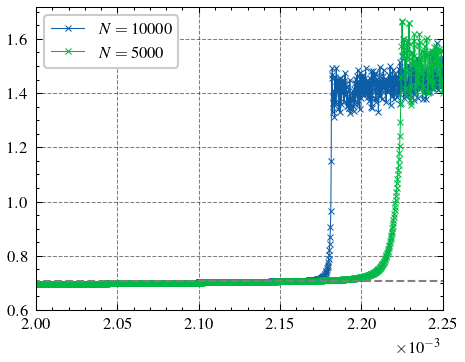

In [46]:
plt.plot(t_1, w_gauss_max_N_1_Nt_1, "x-", lw=.5, markeredgewidth=.5, ms=3, label=r"$N=10000$")
plt.plot(t_1, w_gauss_max_N_2_Nt_1, "x-", lw=.5, markeredgewidth=.5, ms=3, label=r"$N=5000$")

plt.hlines(np.sqrt(2)/2, 0, t[-1], color="gray", ls="--")
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.xlim(2e-3, 2.25e-3)
plt.legend()
#plt.ylim(0.65, 1)
#plt.savefig("gaussian.pdf", dpi=300, bbox_inches = "tight")
plt.show()

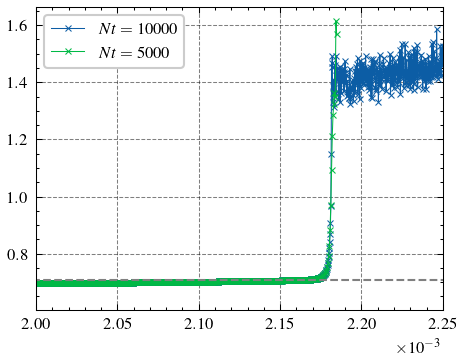

In [54]:
plt.plot(t_1, w_gauss_max_N_1_Nt_1, "x-", lw=.5, markeredgewidth=.5, ms=3, label=r"$Nt=10000$")
plt.plot(t_2[w_gauss_max_N_1_Nt_2>0][:-1], w_gauss_max_N_1_Nt_2[w_gauss_max_N_1_Nt_2>0][:-1], "x-", lw=.5, markeredgewidth=.5, ms=3, label=r"$Nt=5000$")

plt.hlines(np.sqrt(2)/2, 0, t[-1], color="gray", ls="--")
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.xlim(2e-3, 2.25e-3)
plt.legend()
#plt.ylim(0.65, 1)
#plt.savefig("gaussian.pdf", dpi=300, bbox_inches = "tight")
plt.show()

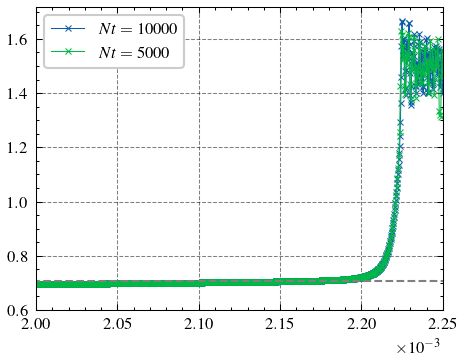

In [50]:
plt.plot(t_1, w_gauss_max_N_2_Nt_1, "x-", lw=.5, markeredgewidth=.5, ms=3, label=r"$Nt=10000$")
plt.plot(t_2, w_gauss_max_N_2_Nt_2, "x-", lw=.5, markeredgewidth=.5, ms=3, label=r"$Nt=5000$")

plt.hlines(np.sqrt(2)/2, 0, t[-1], color="gray", ls="--")
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.xlim(2e-3, 2.25e-3)
plt.legend()
#plt.ylim(0.65, 1)
#plt.savefig("gaussian.pdf", dpi=300, bbox_inches = "tight")
plt.show()

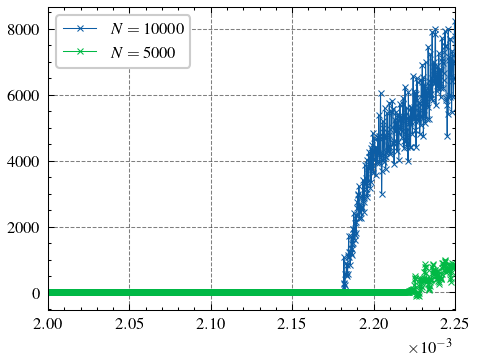

In [27]:
plt.plot(t, energy_N_1, "x-", lw=.5, markeredgewidth=.5, ms=3, label=r"$N=10000$")
plt.plot(t, energy_N_2, "x-", lw=.5, markeredgewidth=.5, ms=3, label=r"$N=5000$")
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.xlim(2e-3, 2.25e-3)
plt.legend()
#plt.ylim(0.65, 1)
#plt.savefig("gaussian.pdf", dpi=300, bbox_inches = "tight")
plt.show()

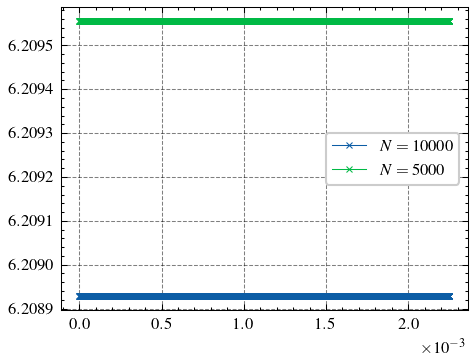

In [25]:
plt.plot(t, mass_N_1, "x-", lw=.5, markeredgewidth=.5, ms=3, label=r"$N=10000$")
plt.plot(t, mass_N_2, "x-", lw=.5, markeredgewidth=.5, ms=3, label=r"$N=5000$")
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.legend()
#plt.savefig("gaussian.pdf", dpi=300, bbox_inches = "tight")
plt.show()